# Mempelajari Penggunaan Drive Neo4J

In [1]:
from neo4j import GraphDatabase, RoutingControl
# Sesuaikan URI dan AUTH credential dengan database Neo4J kamu
URI = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", "Audy77Alycia")

In [2]:
# Fungsi untuk membuat Node & Relationship
def add_friend(driver, name, friend_name):
  driver.execute_query(
      "MERGE (a:Person {name: $name}) "
      "MERGE (friend:Person {name: $friend_name}) "
      "MERGE (a)-[:KNOWS]->(friend)",
      name=name, friend_name=friend_name, database_="neo4j",
  )

In [3]:
# Fungsi untuk membaca data
def print_friends(driver, name):
  records, _, _ = driver.execute_query(
      "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
      "RETURN friend.name ORDER BY friend.name",
      name=name, database_="neo4j", routing_=RoutingControl.READ,
  )
  for record in records:
    print(record["friend.name"])


# Membuka koneksi driver dan mengeksekusi fungsi
if __name__ == "__main__":
  with GraphDatabase.driver(URI, auth=AUTH) as driver:
    add_friend(driver, "Arthur", "Guinevere")
    add_friend(driver, "Arthur", "Lancelot")
    add_friend(driver, "Arthur", "Merlin")

    print("Daftar teman Arthur:")
    print_friends(driver, "Arthur")

Daftar teman Arthur:
Guinevere
Lancelot
Merlin


# Pertanyaan Pendahuluan (Checkpoint)

1. Apa nama database yang digunakan dalam tutorial ini?

**Jawab:** Nama database yang digunakan adalah neo4j, yang merupakan nama database default bawaan dari instance Neo4j, seperti yang terdefinisi pada parameter database_="neo4j" di dalam kode Python.

2. Sebutkan akses lain (seperti sintaks DDL/DML CYPHER) yang dapat digunakan mengakses database lain dalam 1 instance!

**Jawab:** Untuk mengakses ke database lain di dalam 1 instace yang sama menggunakan Cypher berikut.
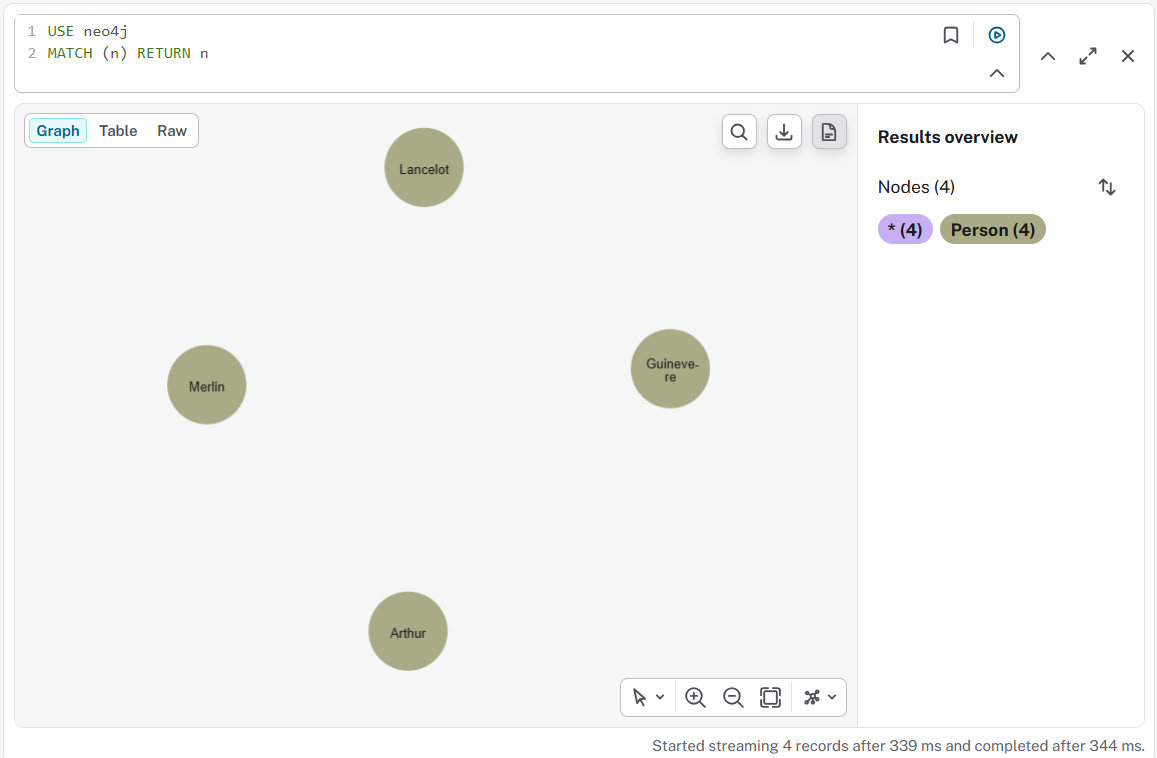

Kemudian ada beberapa perintah DDL/DML yang dapat dilakukan di dalam 1 instance sebagai berikut.

a. Menampilkan semua Database yang ada untuk melihat tabel yang berisi daftar database yang ada di dalam 1 instance seperti database utama dan system.
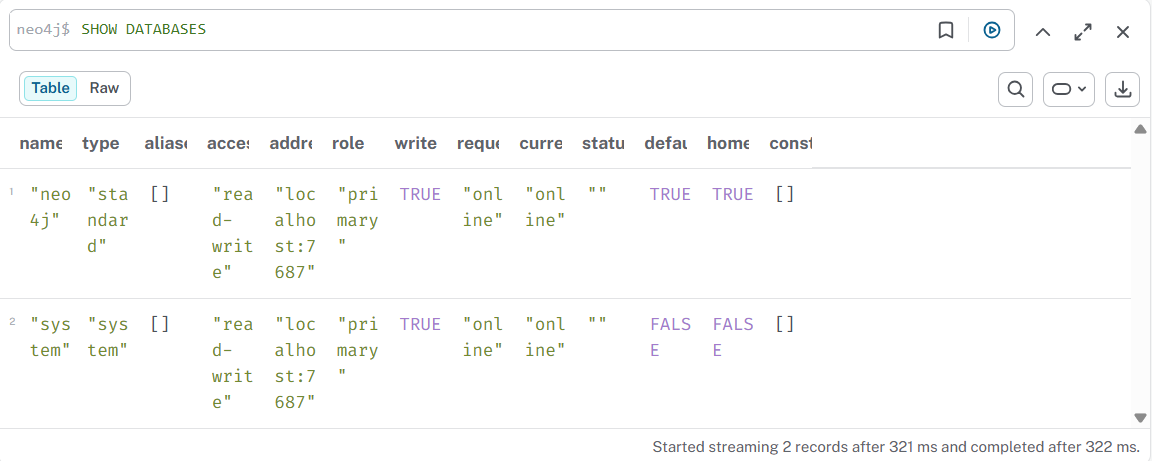

b. Membuat Database baru (demodb)
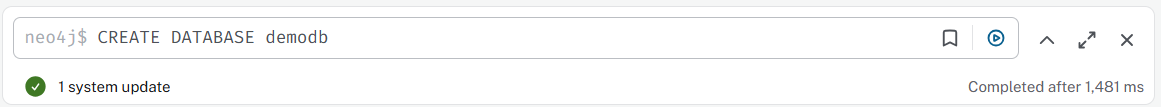

c. Mengisi data khusus di Database baru menggunakan Chyper
Perintah USE demodb memastikan node Budi disimpan di demodb dan bukan di database neo4j utama.
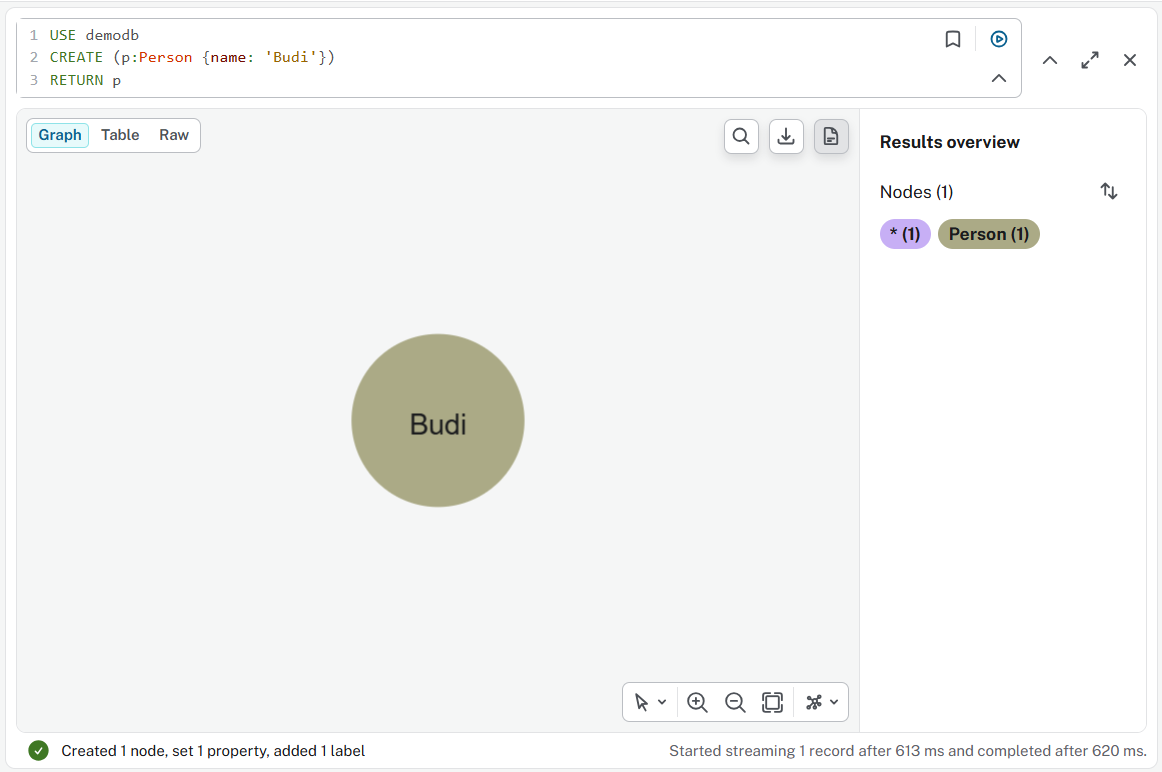

d. Mengubah status Database menjadi Read-Only
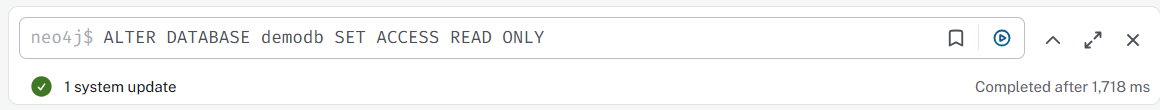

e. Mengembalikan akses ke Read-Write
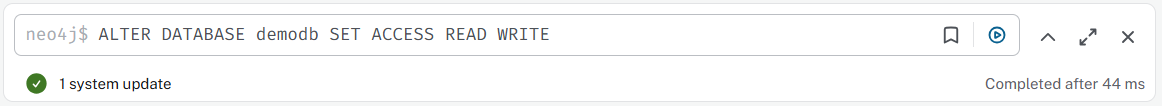

f. Menghapus Database
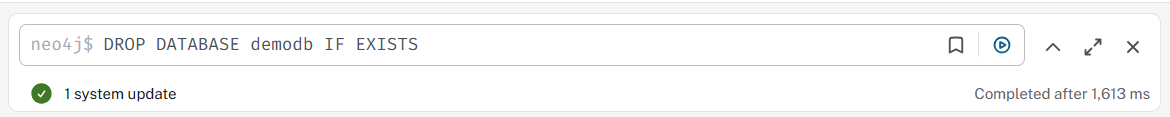

3. Apa jenis graf pertemanan yang telah dibuat di sini?

**Jawab:** Graf pertemanan yang terbentuk merupakan jenis directed graph (graf berarah) dan unweighted (tanpa bobot) yang berbasis Labeled Property Graph. Hal ini terlihat langsung dari panah relasi :KNOWS yang punya arah jelas dari node Arthur menuju ke masing-masing temannya (Lancelot, Guinevere, dan Merlin) tanpa adanya nilai bobot tertentu. Selain itu, graf ini juga bersifat homogen karena seluruh node cuma pakai satu jenis label yaitu Person dan tipe relasinya pun hanya satu, yaitu KNOWS.
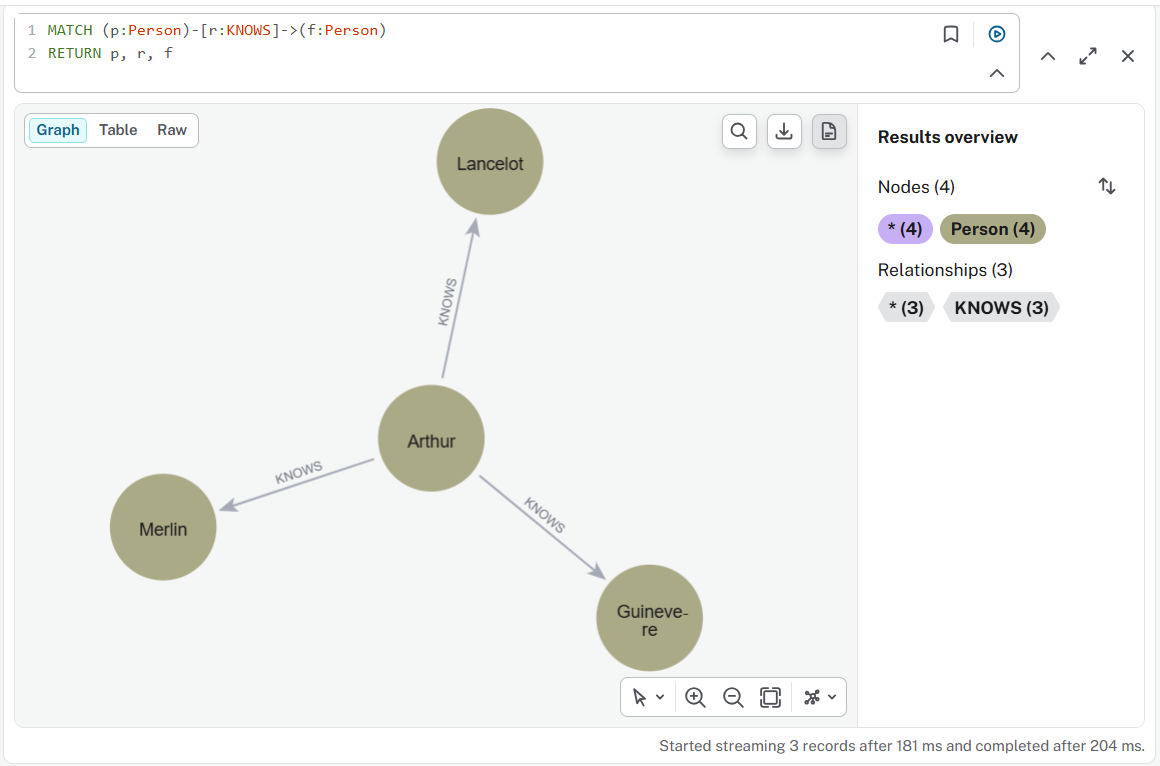

# Cypher Total Reset

Menghapus seluruh isi database neo4j
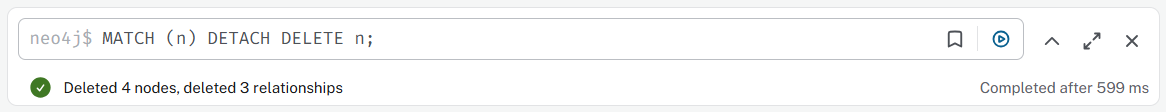